<a href="https://colab.research.google.com/github/gilmorer541-source/quantum-bell-states-analysis/blob/main/QuantumEntanglement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit qiskit-aer matplotlib
!pip install qiskit[visualization] qiskit-aer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 11.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=e535632245f617897ade12886b341044370090c1dc9b89fb1a9a3300f732761c
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


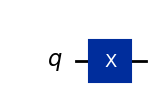

In [ ]:
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import Statevector, DensityMatrix, state_fidelity
from qiskit_aer.noise import amplitude_damping_error, phase_damping_error

qc = QuantumCircuit(1)
qc.x(0)
qc.draw(output ="mpl")

In [ ]:
#first bell state pure
c1= QuantumCircuit(2)
c1.h(0)
c1.cx(0,1)
idc1= Statevector.from_instruction(c1)
print(idc1)

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [ ]:
#second bell state pure
c2 = QuantumCircuit(2)
c2.h(0)
c2.z(0)
c2.cx(0,1)
idc2 = Statevector.from_instruction(c2)
print(idc2)


Statevector([ 0.70710678+0.j,  0.        +0.j,  0.        +0.j,
             -0.70710678+0.j],
            dims=(2, 2))


In [ ]:
#third bell state pure
c3 = QuantumCircuit(2)
c3.x(1)
c3.h(0)
c3.cx(0,1)
idc3 = Statevector.from_instruction(c3)
print(idc3)

Statevector([0.        +0.j, 0.70710678+0.j, 0.70710678+0.j,
             0.        +0.j],
            dims=(2, 2))


In [ ]:
#fourth bell state pure
c4 = QuantumCircuit(2)
c4.x(1)
c4.h(0)
c4.z(0)
c4.cx(0,1)
idc4 = Statevector.from_instruction(c4)
print(idc4)

Statevector([ 0.        +0.j, -0.70710678+0.j,  0.70710678+0.j,
              0.        +0.j],
            dims=(2, 2))


<Figure size 800x500 with 0 Axes>

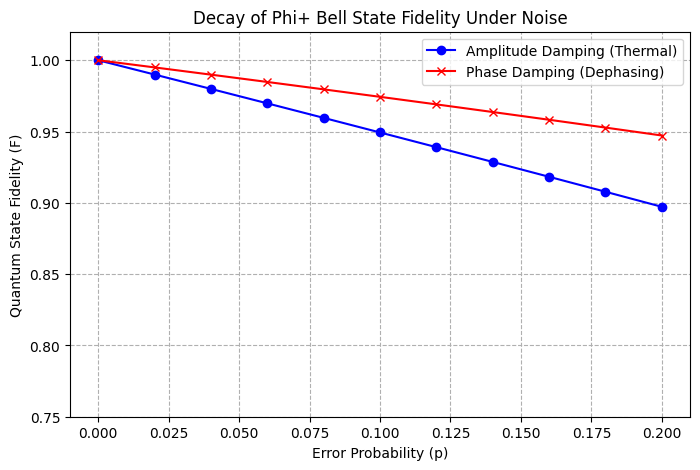

In [ ]:
#Bell State 1 with noise fidelity
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import Statevector, DensityMatrix, state_fidelity
from qiskit_aer.noise import amplitude_damping_error, phase_damping_error
c1 = QuantumCircuit(2)
c1.h(0)
c1.cx(0,1)
idc1  = Statevector.from_instruction(c1)
rho_ideal = DensityMatrix(idc1)
error_rates= np.linspace(0.0,0.20,11)
amplitude_fidelities = []
phase_fidelities = []
for p in error_rates:
  amp_noise_channel = amplitude_damping_error(p).to_quantumchannel()
  rho_noisy_amp = rho_ideal.evolve(amp_noise_channel,[0])
  fid_amp = state_fidelity(rho_ideal,rho_noisy_amp)
  amplitude_fidelities.append(fid_amp)
  phase_noise_channel = phase_damping_error(p).to_quantumchannel()
  rho_noisy_phase = rho_ideal.evolve(phase_noise_channel,[0])
  fid_phase = state_fidelity(rho_ideal, rho_noisy_phase)
  phase_fidelities.append(fid_phase)
plt.figure(figsize=(8,5))
plt.figure(figsize=(8, 5))
plt.plot(error_rates, amplitude_fidelities, label='Amplitude Damping (Thermal)', marker='o', color='blue')
plt.plot(error_rates, phase_fidelities, label='Phase Damping (Dephasing)', marker='x', color='red')
plt.title('Decay of Phi+ Bell State Fidelity Under Noise')
plt.xlabel('Error Probability (p)')
plt.ylabel('Quantum State Fidelity (F)')
plt.ylim(0.75, 1.02)
plt.grid(True, linestyle='--')
plt.legend()
plt.savefig('bell_state_1_noise_decay.png', dpi=300)
plt.show()


<Figure size 800x500 with 0 Axes>

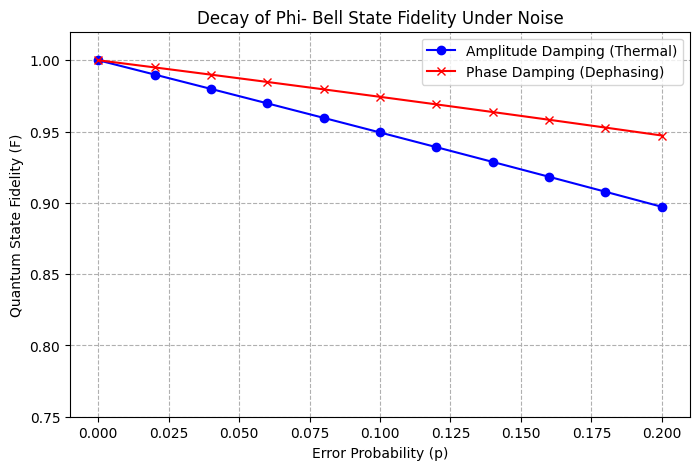

In [ ]:
#Second bell state with noise fidelity
c2 = QuantumCircuit(2)
c2.h(0)
c2.z(0)
c2.cx(0,1)
idc2 = Statevector.from_instruction(c2)
rho_ideal = DensityMatrix(idc2)
error_rates= np.linspace(0.0,0.20,11)
amplitude_fidelities = []
phase_fidelities = []
for p in error_rates:
  amp_noise_channel = amplitude_damping_error(p).to_quantumchannel()
  rho_noisy_amp = rho_ideal.evolve(amp_noise_channel,[0])
  fid_amp = state_fidelity(rho_ideal,rho_noisy_amp)
  amplitude_fidelities.append(fid_amp)
  phase_noise_channel = phase_damping_error(p).to_quantumchannel()
  rho_noisy_phase = rho_ideal.evolve(phase_noise_channel,[0])
  fid_phase = state_fidelity(rho_ideal, rho_noisy_phase)
  phase_fidelities.append(fid_phase)
plt.figure(figsize=(8,5))
plt.figure(figsize=(8, 5))
plt.plot(error_rates, amplitude_fidelities, label='Amplitude Damping (Thermal)', marker='o', color='blue')
plt.plot(error_rates, phase_fidelities, label='Phase Damping (Dephasing)', marker='x', color='red')
plt.title('Decay of Phi- Bell State Fidelity Under Noise')
plt.xlabel('Error Probability (p)')
plt.ylabel('Quantum State Fidelity (F)')
plt.ylim(0.75, 1.02)
plt.grid(True, linestyle='--')
plt.legend()
plt.savefig('bell_state_2_noise_decay.png', dpi=300)
plt.show()

<Figure size 800x500 with 0 Axes>

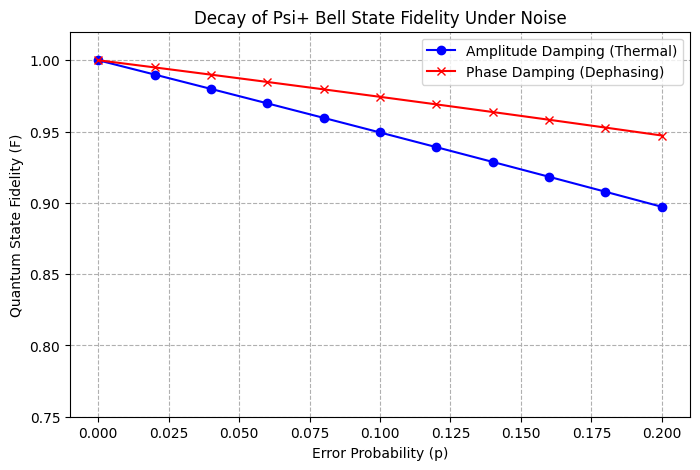

In [ ]:
#Third bell state with noise fidelity
c3 = QuantumCircuit(2)
c3.x(1)
c3.h(0)
c3.cx(0,1)
idc3 = Statevector.from_instruction(c3)
rho_ideal = DensityMatrix(idc3)
error_rates= np.linspace(0.0,0.20,11)
amplitude_fidelities = []
phase_fidelities = []
for p in error_rates:
  amp_noise_channel = amplitude_damping_error(p).to_quantumchannel()
  rho_noisy_amp = rho_ideal.evolve(amp_noise_channel,[0])
  fid_amp = state_fidelity(rho_ideal,rho_noisy_amp)
  amplitude_fidelities.append(fid_amp)
  phase_noise_channel = phase_damping_error(p).to_quantumchannel()
  rho_noisy_phase = rho_ideal.evolve(phase_noise_channel,[0])
  fid_phase = state_fidelity(rho_ideal, rho_noisy_phase)
  phase_fidelities.append(fid_phase)
plt.figure(figsize=(8,5))
plt.figure(figsize=(8, 5))
plt.plot(error_rates, amplitude_fidelities, label='Amplitude Damping (Thermal)', marker='o', color='blue')
plt.plot(error_rates, phase_fidelities, label='Phase Damping (Dephasing)', marker='x', color='red')
plt.title('Decay of Psi+ Bell State Fidelity Under Noise')
plt.xlabel('Error Probability (p)')
plt.ylabel('Quantum State Fidelity (F)')
plt.ylim(0.75, 1.02)
plt.grid(True, linestyle='--')
plt.legend()
plt.savefig('bell_state_3_noise_decay.png', dpi=300)
plt.show()

<Figure size 800x500 with 0 Axes>

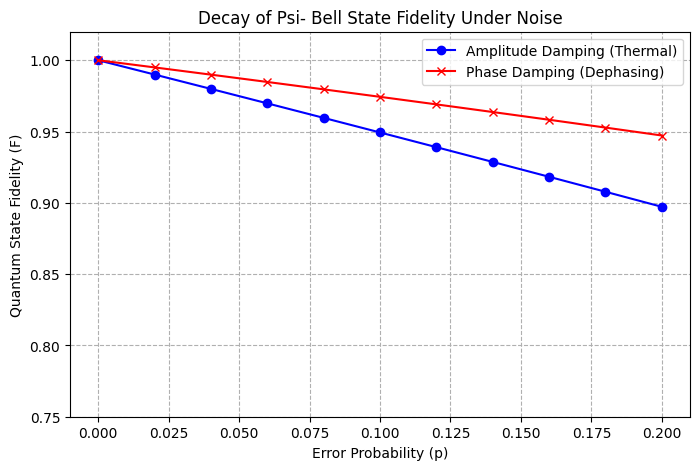

In [ ]:
c4 = QuantumCircuit(2)
c4.x(1)
c4.h(0)
c4.z(0)
c4.cx(0,1)
idc4 = Statevector.from_instruction(c4)
rho_ideal = DensityMatrix(idc4)
error_rates= np.linspace(0.0,0.20,11)
amplitude_fidelities = []
phase_fidelities = []
for p in error_rates:
  amp_noise_channel = amplitude_damping_error(p).to_quantumchannel()
  rho_noisy_amp = rho_ideal.evolve(amp_noise_channel,[0])
  fid_amp = state_fidelity(rho_ideal,rho_noisy_amp)
  amplitude_fidelities.append(fid_amp)
  phase_noise_channel = phase_damping_error(p).to_quantumchannel()
  rho_noisy_phase = rho_ideal.evolve(phase_noise_channel,[0])
  fid_phase = state_fidelity(rho_ideal, rho_noisy_phase)
  phase_fidelities.append(fid_phase)
plt.figure(figsize=(8,5))
plt.figure(figsize=(8, 5))
plt.plot(error_rates, amplitude_fidelities, label='Amplitude Damping (Thermal)', marker='o', color='blue')
plt.plot(error_rates, phase_fidelities, label='Phase Damping (Dephasing)', marker='x', color='red')
plt.title('Decay of Psi- Bell State Fidelity Under Noise')
plt.xlabel('Error Probability (p)')
plt.ylabel('Quantum State Fidelity (F)')
plt.ylim(0.75, 1.02)
plt.grid(True, linestyle='--')
plt.legend()
plt.savefig('bell_state_4_noise_decay.png', dpi=300)
plt.show()
